# 01 · Clean development metadata and retain exact copies once

Check the same metadata rules as the original cleaning notebook, then apply one frozen image-content retention rule. Every later stage uses its retained IDs.

Read the stages in numerical order. Training uses separate, explicitly invoked runners; executing this notebook only loads development data and saved artifacts.

Original notebooks, images, checkpoints and results remain available. The reserved test is outside this workflow.

**Original methods and figure reference:** [01_data_cleaning.ipynb](../Subset/01_data_cleaning.ipynb). Read [method coverage](METHOD_COVERAGE.md) for retained methods and declared adaptations.

## Load the frozen clean development dataset

In [1]:
NOTEBOOK_STAGE = '01_data_cleaning'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
FIGURE_DIR = ROOT / DIRECTORY / "figures" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=180, bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

## 1. Trace the inputs and outputs

An image is one observation; a patient can contribute several observations. The ledger defines the original development population before any source check. The manifest identifies source bytes, retained IDs and preserved memberships. This reader verifies the frozen cleaning output; it does not rewrite the source or select a new variant.

In [2]:
from melanoma_detection.development_dataset import sha256_file
ledger = context["ledger"]
original_ids = set(ledger.image_name)
source = pd.read_csv(ROOT / "data/subset/train_labels.csv", dtype={"target": "string"})
source = source.loc[source.image_name.isin(original_ids)].copy()
original_clean = pd.read_csv(ROOT / "data/subset/processed/train_clean.csv")
original_clean = original_clean.loc[original_clean.image_name.isin(original_ids)].copy()
assert len(source) == len(original_clean) == len(ledger) == 6864
assert source.image_name.is_unique and original_clean.image_name.is_unique
for relative, digest in context["manifest"]["audited_input_sha256"].items():
    assert sha256_file(ROOT / relative) == digest, "Audited source changed: " + relative
display(pd.DataFrame([{"input": "Original development source", "rows": len(source)},
    {"input": "Original cleaned development", "rows": len(original_clean)},
    {"input": "Frozen retained development", "rows": len(data)}]))
display(pd.DataFrame([{"manifest_sha256": dataset_identity["dataset_manifest_sha256"],
    "retention_rule": context["manifest"]["retention_rule"], "fingerprint_version": context["manifest"]["fingerprint_version"]}]))

,input,rows
0,Original development source,6864
1,Original cleaned development,6864
2,Frozen retained development,6706


,manifest_sha256,retention_rule,fingerprint_version
0,9f7f0f3bfc436b90372c76c6925fbc12cdd8a413556d7e...,lexicographically_smallest_image_name_per_conf...,sha256_str_dimensions_plus_decoded_rgb_v1


## 2. Read the schema and missingness

As in the original, inspect exact field counts before changing values. Unknown preserves missing information; it does not infer a patient's site or age. Model preprocessing is fitted later using training patients only. Diagnosis and benign/malignant descriptions are consistency checks, never predictors.

In [3]:
features = ["sex", "age_approx", "anatom_site_general_challenge"]
display(pd.DataFrame({"dtype": data.dtypes.astype(str), "filled": data.notna().sum(),
    "distinct_values": data.nunique(dropna=False)}))
display(data.head())
def unknown_mask(values):
    return values.isna() | values.astype("string").str.strip().str.casefold().isin(
        ["", "unknown", "nan", "none", "null", "missing", "n/a", "na"])
rows = []
for column in features:
    rows.append({"field": column, "source_missing": int(unknown_mask(source[column]).sum()),
        "original_clean_unknown": int(unknown_mask(original_clean[column]).sum()),
        "retained_unknown": int(unknown_mask(data[column]).sum())})
display(pd.DataFrame(rows))

,dtype,filled,distinct_values
image_name,str,6706,6706
patient_id,str,6706,422
sex,str,6706,2
age_approx,int64,6706,16
anatom_site_general_challenge,str,6706,7
diagnosis,str,6706,8
benign_malignant,str,6706,2
target,int8,6706,2
fold,int64,6706,5


,image_name,patient_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target,fold
0,ISIC_0015719,IP_3075186,female,45,upper extremity,unknown,benign,0,0
1,ISIC_0074542,IP_4698288,male,25,lower extremity,unknown,benign,0,1
2,ISIC_0076545,IP_9802602,male,55,upper extremity,unknown,benign,0,2
3,ISIC_0082348,IP_7684360,male,55,torso,unknown,benign,0,0
4,ISIC_0085172,IP_1705144,female,50,lower extremity,unknown,benign,0,1


,field,source_missing,original_clean_unknown,retained_unknown
0,sex,0,0,0
1,age_approx,0,0,0
2,anatom_site_general_challenge,196,196,195


## 3. Verify label, category and age rules

Labels must be exactly 0 or 1 before conversion. Known ages use the recorded five-year buckets between 0 and 120. Strip surrounding whitespace for the check; preserve the established cleaned values. Passing these checks establishes format and agreement, not clinical correctness.

In [4]:
from melanoma_detection.metadata_validation import validate_binary_target
source_targets = validate_binary_target(source.target)
ages = pd.to_numeric(data.age_approx, errors="coerce")
known_age = ~unknown_mask(data.age_approx)
expected_sites = {"head/neck", "lower extremity", "oral/genital", "palms/soles", "torso", "upper extremity", "Unknown"}
checks = {
    "duplicate image IDs": int(data.image_name.duplicated().sum()),
    "missing patient IDs": int(data.patient_id.isna().sum()),
    "invalid labels": int(~data.target.isin([0, 1]).all()),
    "malformed known ages": int((known_age & ages.isna()).sum()),
    "ages outside 0–120": int((known_age & ~ages.between(0, 120)).sum()),
    "ages outside five-year buckets": int((known_age & ages.mod(5).ne(0)).sum()),
    "unexpected sex": int(~data.sex.isin(["female", "male", "Unknown"]).all()),
    "unexpected site": int(~data.anatom_site_general_challenge.isin(expected_sites).all()),
    "target/description conflicts": int(data.benign_malignant.ne(data.target.map({0:"benign",1:"malignant"})).sum())}
display(pd.Series(checks, name="problem_count").to_frame())
assert not any(checks.values())
source.target = source_targets
for column in ["patient_id", "target"]:
    a = source.set_index("image_name").loc[data.image_name, column].astype(str).to_numpy()
    assert np.array_equal(a, data[column].astype(str).to_numpy())
for column in features:
    a = original_clean.set_index("image_name").loc[data.image_name, column].astype(str).to_numpy()
    assert np.array_equal(a, data[column].astype(str).to_numpy())

,problem_count
duplicate image IDs,0
missing patient IDs,0
invalid labels,0
malformed known ages,0
ages outside 0–120,0
ages outside five-year buckets,0
unexpected sex,0
unexpected site,0
target/description conflicts,0


## 4. Define exact copies and a deterministic representative

A file hash identifies byte copies; the full-resolution decoded RGB fingerprint also detects identical pixels stored differently. Pixel equality confirms every group. For each group, the smallest image ID is kept, without scores, predictions or model performance. A coarse similarity hash and identical metadata alone cannot remove a row.

In [5]:
excluded = ledger.loc[ledger.decision.eq("excluded")]
grouped = ledger.groupby("retained_image_name")
duplicates = grouped.filter(lambda rows: len(rows) > 1)
group_checks = []
for representative, rows in duplicates.groupby("retained_image_name"):
    assert representative == min(rows.image_name)
    assert rows.pixel_sha256.nunique() == 1
    assert rows.patient_id.nunique() == rows.target.nunique() == rows.fold.nunique() == 1
    metadata_rows = original_clean.set_index("image_name").loc[rows.image_name, features]
    assert metadata_rows.nunique(dropna=False).eq(1).all()
    assert rows.decision.eq("retained").sum() == 1
    group_checks.append({"representative": representative, "copies": len(rows), "patient": rows.patient_id.iloc[0],
        "label": rows.target.iloc[0], "file_hashes": rows.source_sha256.nunique()})
display(pd.DataFrame(group_checks).head(12))
display(pd.DataFrame([{"confirmed_groups": len(group_checks), "excluded": len(excluded),
    "excluded_benign": int(excluded.target.eq(0).sum()), "excluded_malignant": int(excluded.target.eq(1).sum())}]))
assert len(group_checks) == len(excluded) == 158

,representative,copies,patient,label,file_hashes
0,ISIC_0087297,2,IP_5389392,0,1
1,ISIC_0112097,2,IP_5889408,0,1
2,ISIC_0148783,2,IP_4488328,0,1
3,ISIC_0157530,2,IP_4488328,0,1
4,ISIC_0196945,2,IP_5389392,0,1
5,ISIC_0207209,2,IP_4488328,0,1
6,ISIC_0213336,2,IP_5889408,0,1
7,ISIC_0238002,2,IP_4488328,0,1
8,ISIC_0308133,2,IP_9422872,0,1
9,ISIC_0313653,2,IP_3751991,0,1


,confirmed_groups,excluded,excluded_benign,excluded_malignant
0,158,158,157,1


## 5. Inspect an identical pair and a distinct review pair

This deterministic contact sheet is a worked example of the rule. The top row is the first exact-copy group by ID; the lower row is the manually merged pair from the reference notebook. Its photographs differ, so both remain. Displaying a pair is supporting evidence; the decision rests on full pixel equality, not visual similarity.

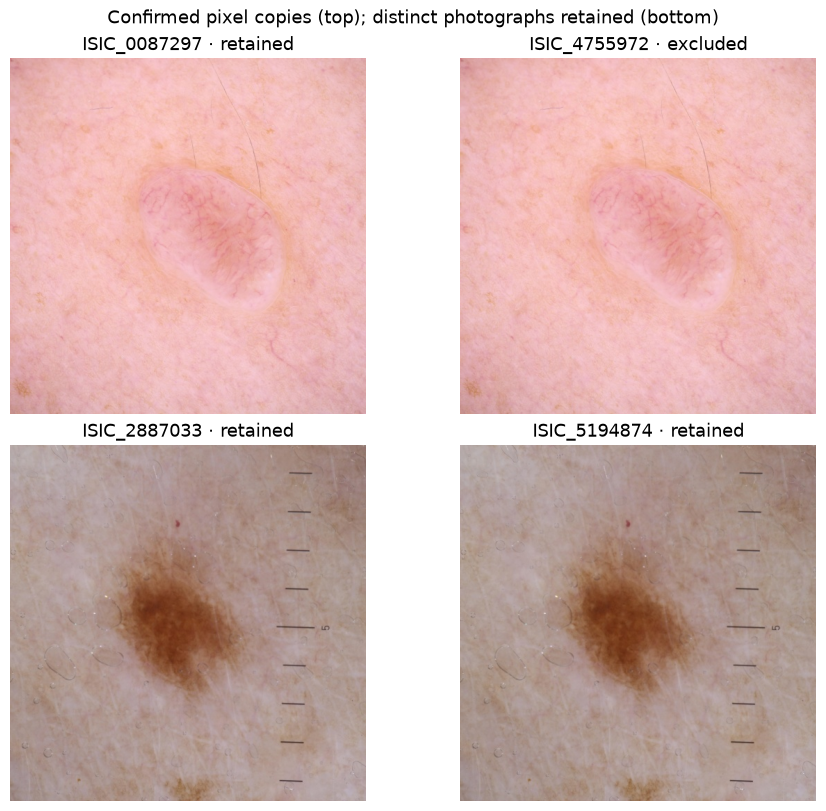

In [6]:
from PIL import Image as PILImage
exact = duplicates.sort_values("image_name").retained_image_name.iloc[0]
exact_ids = sorted(duplicates.loc[duplicates.retained_image_name.eq(exact), "image_name"])
distinct_ids = ["ISIC_2887033", "ISIC_5194874"]
assert set(distinct_ids).issubset(set(data.image_name))
fig, axes = plt.subplots(2, 2, figsize=(9, 8), layout="constrained")
full_pixels = {}
for axis, image_id in zip(axes.flat, exact_ids + distinct_ids):
    with PILImage.open(ROOT / "data/subset/train" / (image_id + ".jpg")) as opened:
        pixels = np.asarray(opened.convert("RGB"))
        full_pixels[image_id] = pixels
        axis.imshow(pixels)
    row = ledger.set_index("image_name").loc[image_id]
    axis.set_title(image_id + " · " + row.decision); axis.axis("off")
fig.suptitle("Confirmed pixel copies (top); distinct photographs retained (bottom)")
finish_figure(fig, "exact_and_distinct_examples")
assert np.array_equal(full_pixels[exact_ids[0]], full_pixels[exact_ids[1]])
assert not np.array_equal(full_pixels[distinct_ids[0]], full_pixels[distinct_ids[1]])
assert ledger.set_index("image_name").loc[distinct_ids].pixel_sha256.nunique() == 2

## 6. Check retention, fold counts and verification receipts

Retained and excluded IDs must partition all 6,864 original development IDs. All 422 patients and all 88 malignant patients remain. The full cleaning receipt records decoding and source agreement. No images were deleted; every model filters through the same manifest.

In [7]:
retained = ledger.loc[ledger.decision.eq("retained")]
assert set(retained.image_name).isdisjoint(set(excluded.image_name))
assert set(retained.image_name) | set(excluded.image_name) == original_ids
assert set(data.image_name) == set(retained.image_name)
assert len(data) == 6706 and int(data.target.sum()) == 127
assert data.patient_id.nunique() == 422 and data.loc[data.target.eq(1), "patient_id"].nunique() == 88
display(context["fold_counts"])
receipt = read_json(ROOT / DIRECTORY / "cleaning/receipt.json")
assert receipt["dataset_identity"] == dataset_identity
display(pd.DataFrame([{k:receipt[k] for k in ["status", "sources_verified", "pixels_verified", "all_outer_and_preserved_inner_assignments_verified"]}]))
display(ledger[["width", "height"]].value_counts().rename("decoded_images").reset_index())

,fold,images_before,malignant_images_before,patients_before,images_after,malignant_images_after,patients_after,excluded_images,excluded_malignant
0,0,1370,25,84,1344,24,84,26,1
1,1,1372,26,84,1366,26,84,6,0
2,2,1381,26,87,1328,26,87,53,0
3,3,1371,25,82,1371,25,82,0,0
4,4,1370,26,85,1297,26,85,73,0


,status,sources_verified,pixels_verified,all_outer_and_preserved_inner_assignments_verified
0,complete,10,6864,True


,width,height,decoded_images
0,512,512,6864


## 7. Preserve unusual metadata rather than guessing

Recorded ages can vary within a patient; missing sites may depend on patient, fold or label. Such patterns need documentation, not automatic correction. Multiple photographs or visits can explain differences, and dates are unavailable. Deterministic examples make the caveat inspectable.

In [8]:
profiles = pd.read_csv(ROOT / "results/dedup_v1/audit/patient_profile_retained.csv")
display(profiles.loc[profiles.distinct_ages.gt(1)].sort_values(["age_span", "patient_id"], ascending=[False, True]).head(12))
display(pd.DataFrame([{"patients_with_multiple_ages": int(profiles.distinct_ages.gt(1).sum()),
    "patients_age_span_at_least_15": int(profiles.age_span.ge(15).sum()),
    "unknown_site_patients": int(profiles.missing_site.gt(0).sum())}]))
show_saved_table("results/dedup_v1/audit/missing_site_by_fold_label_retained.csv")

,patient_id,images,malignant_images,fold,age_min,age_max,distinct_ages,missing_site,age_span
2,IP_0148558,35,0,0,35,55,5,0,20
27,IP_0843629,32,0,4,25,45,5,0,20
45,IP_1253185,36,0,3,25,45,5,0,20
51,IP_1512731,37,2,4,25,45,5,0,20
53,IP_1557123,15,0,2,25,45,2,0,20
81,IP_2166250,40,0,4,25,45,5,0,20
90,IP_2322991,31,0,3,45,65,5,0,20
111,IP_2738065,40,0,1,15,35,5,0,20
141,IP_3370847,29,0,1,25,45,5,0,20
165,IP_3846489,23,0,1,35,55,5,0,20


,patients_with_multiple_ages,patients_age_span_at_least_15,unknown_site_patients
0,204,41,53


,fold,target,site_missing,images,patients
0,0,0,False,1287,84
1,0,0,True,33,15
2,0,1,False,23,16
3,0,1,True,1,1
4,1,0,False,1331,84
5,1,0,True,9,7
6,1,1,False,26,15
7,2,0,False,1278,87
8,2,0,True,24,13
9,2,1,False,25,21


,fold,target,site_missing,images,patients
0,0,0,False,1287,84
1,0,0,True,33,15
2,0,1,False,23,16
3,0,1,True,1,1
4,1,0,False,1331,84
5,1,0,True,9,7
6,1,1,False,26,15
7,2,0,False,1278,87
8,2,0,True,24,13
9,2,1,False,25,21


## 8. Review image quality and the historical transform

The original preparation and rotation are preserved for replication. Near-white area, low adjacent-pixel variation and dark borders generate review candidates only. The transform sheet shows the possible black corners and clipping from nearest-neighbour rotation with black fill and no expansion. Revising it would be a separate experiment.

,angle_degrees,changes_to_historical_transform,expand,fill,interpretation,resize,rotation_interpolation
0,20,False,False,black,black corners and potential edge clipping need...,224,nearest


### Washed-out review candidates

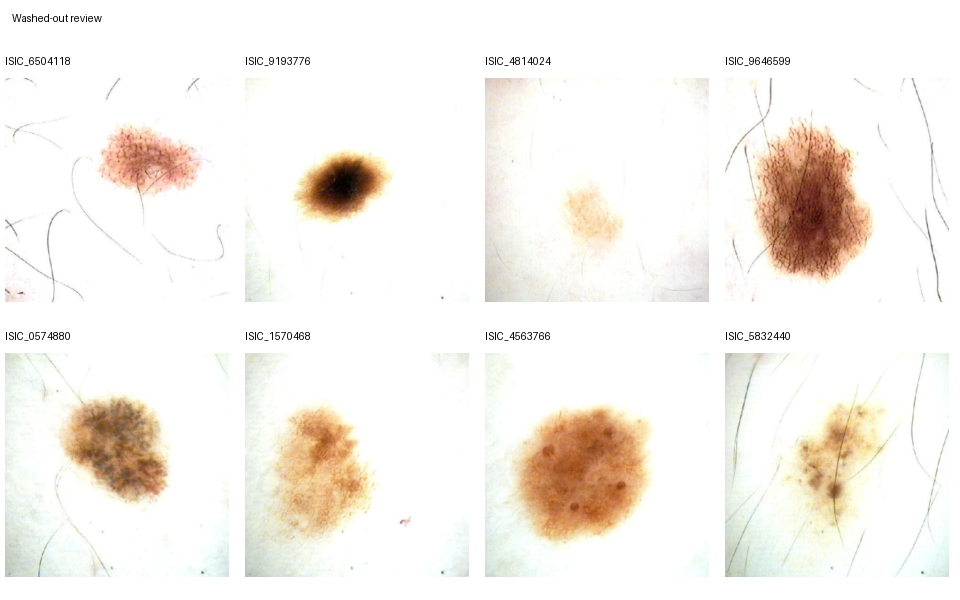

### Low-detail review candidates

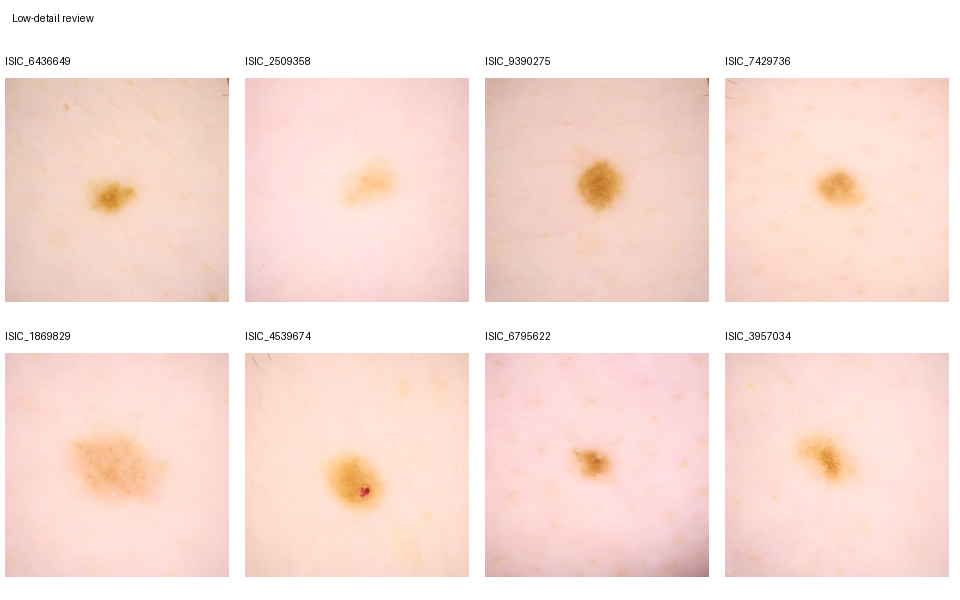

### Border-heavy review candidates

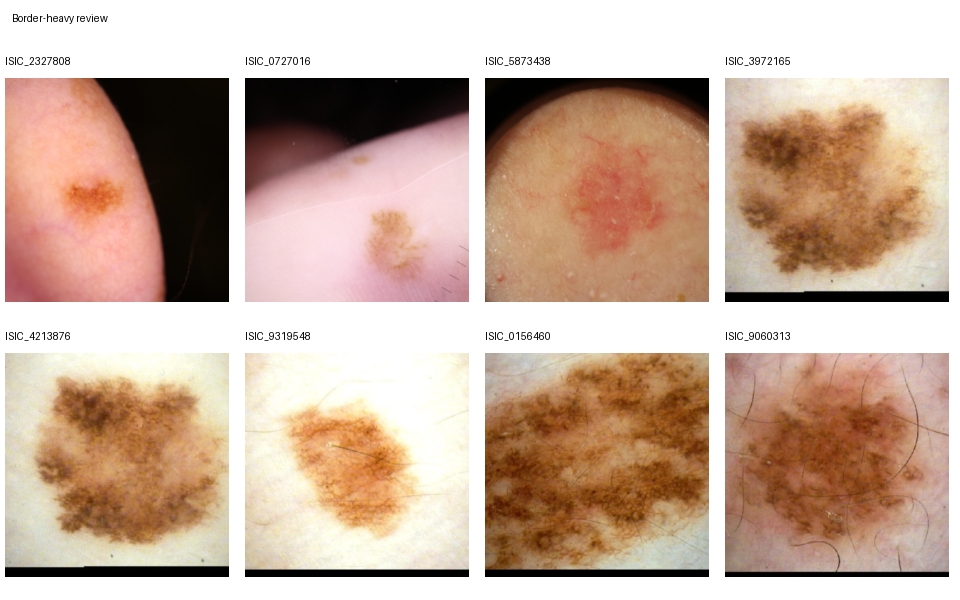

### Historical weak rotation

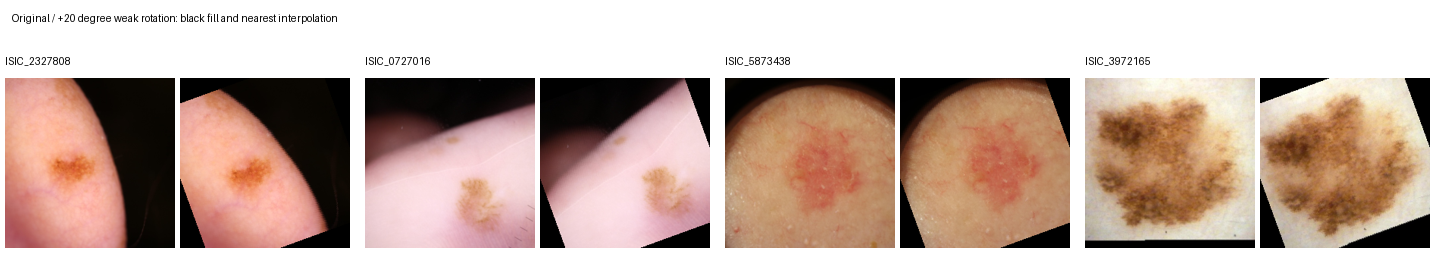

**Cleaning outcome:** 6,706 images; 127 malignant images; 422 patients. No additional quality or similarity exclusions. Proceed to EDA, then verify the preserved folds.

In [9]:
audit = read_json(ROOT / "results/dedup_v1/audit/audit_summary.json")
display(pd.DataFrame([audit["weak_rotation_review"]]))
for filename, title in [("near_white_fraction.png", "Washed-out review candidates"),
    ("gradient_proxy.png", "Low-detail review candidates"), ("near_black_border_fraction.png", "Border-heavy review candidates"),
    ("weak_rotation_review.png", "Historical weak rotation")]:
    display(Markdown("### " + title))
    display(Image(filename=str(ROOT / "results/dedup_v1/audit/figures" / filename)))
display(Markdown("**Cleaning outcome:** 6,706 images; 127 malignant images; 422 patients. No additional quality or similarity exclusions. Proceed to EDA, then verify the preserved folds."))

## Interpretation boundary

These are development results. Patient grouping protects separation between fitting and validation; bootstrap intervals condition on saved models. Sparse subgroups and selected inner-validation pilots cannot establish a final winner. No reserved-test conclusion is made.